In [1]:
import numpy as np
import random
import torch

from models import CNN1dRegressor
from utils import (generate_data_nn, get_gradient, get_hessian, get_full_ggn, get_sorted_hessian_block_mask, distort_model, get_data_loaders, plot_cov_matrices, plot_cov_gnn_hess_matrices)

In [2]:
# fix seeds in numpy and torch
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

In [3]:
def compare_cov_and_ggn(model, train_dataloader, batch_size, class_task=False):
    gradients_noisy, gradients_clean, hessians_clean, ggn_list = [], [], [], []
    for x_batch, y_batch, _ in train_dataloader:
        # get noisy targets
        noise_unit = torch.randn(size=y_batch.shape)
        if class_task:
            pred = model(x_batch)
            v = torch.sqrt(torch.sigmoid(pred) * (1. - torch.sigmoid(pred))).detach()
            noise = np.sqrt(batch_size) * noise_unit * v
        else:
            noise = np.sqrt(batch_size) * noise_unit

        y_batch_noisy = y_batch + noise
        grad_noisy = get_gradient(model, x_batch, y_batch_noisy.detach(), class_task=class_task)
        gradients_noisy.append(grad_noisy)

        hessian_clean = get_hessian(model, x_batch, y_batch.detach(), class_task=class_task)
        hessians_clean.append(hessian_clean)

        ggn = get_full_ggn(model, x_batch, class_task=class_task)
        ggn_list.append(ggn)

    gradients_noisy = torch.stack(gradients_noisy, dim=0).T
    grad_cov_noisy = torch.cov(gradients_noisy)
    grad_cov_noisy = grad_cov_noisy.float()

    hessian = torch.mean(torch.stack(hessians_clean, dim=0), dim=0).detach()
    print(ggn_list[0].shape)
    ggn_matr = torch.mean(torch.stack(ggn_list, dim=0), dim=0).detach()
    print("Final shape of GGN", ggn_matr.shape)

    diff = torch.linalg.norm(grad_cov_noisy - hessian, ord=2)
    diff_rel = diff / torch.linalg.norm(hessian, ord=2)

    print(f"GNN matr shape = {ggn_matr.shape}")
    print(f"Hessian shape = {hessian.shape}")
    diff_ggn = torch.linalg.norm(ggn_matr - hessian, ord=2)
    diff_ggn_rel = diff_ggn / torch.linalg.norm(hessian, ord=2)
    print(f"diff: NC, GN = {diff} vs {diff_ggn}")
    print(f"diff_rel: NC, GN  = {diff_rel} vs {diff_ggn_rel}")

    # calculate differences between blocks with naive implementation of matrix mask
    binary_mask = get_sorted_hessian_block_mask(model)
    block_diff = torch.linalg.norm((grad_cov_noisy - hessian) * binary_mask, ord=2)
    block_diff_rel = block_diff / torch.linalg.norm(hessian * binary_mask, ord=2)
    block_diff_ggn = torch.linalg.norm((ggn_matr - hessian) * binary_mask, ord=2)
    block_diff_ggn_rel = block_diff_ggn / torch.linalg.norm(hessian * binary_mask, ord=2)
    print(f"block diff: NC, GN = {block_diff} vs {block_diff_ggn}")
    print(f"block diff_rel: NC, GN  = {block_diff_rel} vs {block_diff_ggn_rel}")

    grad_cov_noisy_eigv = torch.linalg.eigvalsh(grad_cov_noisy)
    hess_eigv = torch.linalg.eigvalsh(hessian)
    ggn_eigv = torch.linalg.eigvalsh(ggn_matr)
    hess_eigv_relu = torch.relu(hess_eigv)

    print(f"Hessian eigv:")
    print([f"{x:.5f}" for x in sorted(hess_eigv.numpy())])
    print()
    print(f"Noisy grad cov eigv:")
    print([f"{x:.5f}" for x in sorted(grad_cov_noisy_eigv.numpy())])
    print()
    print(f"GGN eigv:")
    print([f"{x:.5f}" for x in sorted(ggn_eigv.numpy())])
    print()

    grad_cov_hess_eigv_diff_rel = torch.linalg.norm(grad_cov_noisy_eigv - hess_eigv_relu, ord=2) / torch.linalg.norm(hess_eigv_relu, ord=2)
    ggn_hess_eigv_diff_rel = torch.linalg.norm(ggn_eigv - hess_eigv_relu, ord=2) / torch.linalg.norm(hess_eigv_relu, ord=2)
    print(f"Eigv diff rel (noisy cov vs Hessian) = {grad_cov_hess_eigv_diff_rel}")
    print(f"Eigv diff rel (GGN vs Hessian) = {ggn_hess_eigv_diff_rel}")

    # eigenvalues of the block diagonal
    block_diag_hessian_eigv = torch.linalg.eigvalsh(hessian * binary_mask)
    print(f"Block diag eigv (hessian):")
    print([f"{x:.5f}" for x in sorted(block_diag_hessian_eigv.numpy())])

    if hessian.shape[0] <= 20:
        class_id = "class" if class_task else "reg"
        plot_cov_matrices(grad_cov_noisy, hessian, filename=f"cnn_cov_{class_id}.pdf", use_cbar=False)
        plot_cov_gnn_hess_matrices(grad_cov_noisy, ggn_matr, hessian, filename=f"cnn_ggn_vs_hessian_{class_id}.pdf", use_cbar=False)


def test_ggn(model_gen, X, y, batch_size=128, dist_norm_w=0.5, class_task=False):
    model_dist = distort_model(model_gen, dist_norm_w)
    train_dataloader, _ = get_data_loaders(X, y[:, None], batch_size=batch_size, test_ratio=0.0)
    compare_cov_and_ggn(model_dist, train_dataloader, batch_size=batch_size, class_task=class_task)

## Calculate GGN (or Fisher) explicitly for the small networks

## Test for classification task

In [4]:
class_task = True
n_features = 8
n_samples = 10000
cnn_gen = CNN1dRegressor(in_channels=1, out_channels=2, kernel_size=3, n_layers=1, seq_len=n_features, pool_size=3)
X, y = generate_data_nn(cnn_gen, n_samples=n_samples, n_features=n_features, noise_std=0.01, scale=3, class_task=class_task)

Classification task: True
Total number of model parameters: 12
torch.Size([12, 12])
Final shape of GGN torch.Size([12, 12])
GNN matr shape = torch.Size([12, 12])
Hessian shape = torch.Size([12, 12])
diff: NC, GN = 3.5821080207824707 vs 3.5655295848846436
diff_rel: NC, GN  = 0.8247888684272766 vs 0.820971667766571
block diff: NC, GN = 0.17458900809288025 vs 0.012480118311941624
block diff_rel: NC, GN  = 0.23819954693317413 vs 0.017027180641889572
Hessian eigv:
['-3.47673', '-3.29702', '-0.10870', '-0.01392', '0.00116', '0.00953', '0.03993', '0.32296', '0.51043', '0.59649', '3.59210', '4.34306']

Noisy grad cov eigv:
['0.00000', '0.00000', '0.00018', '0.00318', '0.00918', '0.02301', '0.03846', '0.04966', '0.28225', '0.51344', '0.61115', '1.26821']

GGN eigv:
['-0.00000', '0.00000', '0.00019', '0.00391', '0.00774', '0.01996', '0.04089', '0.04502', '0.23576', '0.40500', '0.52582', '1.25778']

Eigv diff rel (noisy cov vs Hessian) = 0.7540995478630066
Eigv diff rel (GGN vs Hessian) = 0.76696

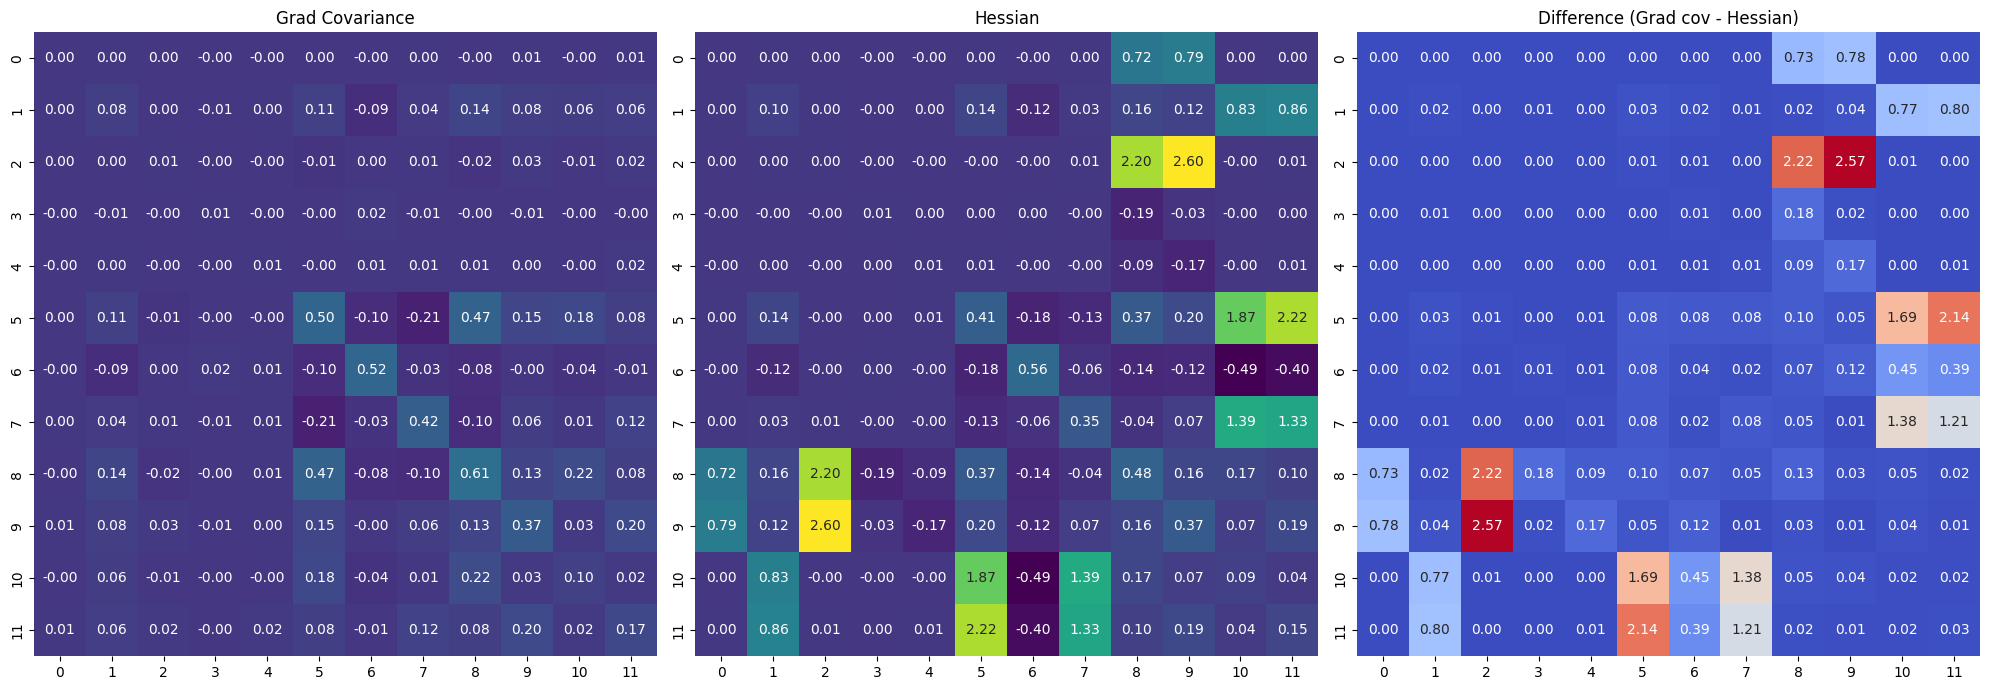

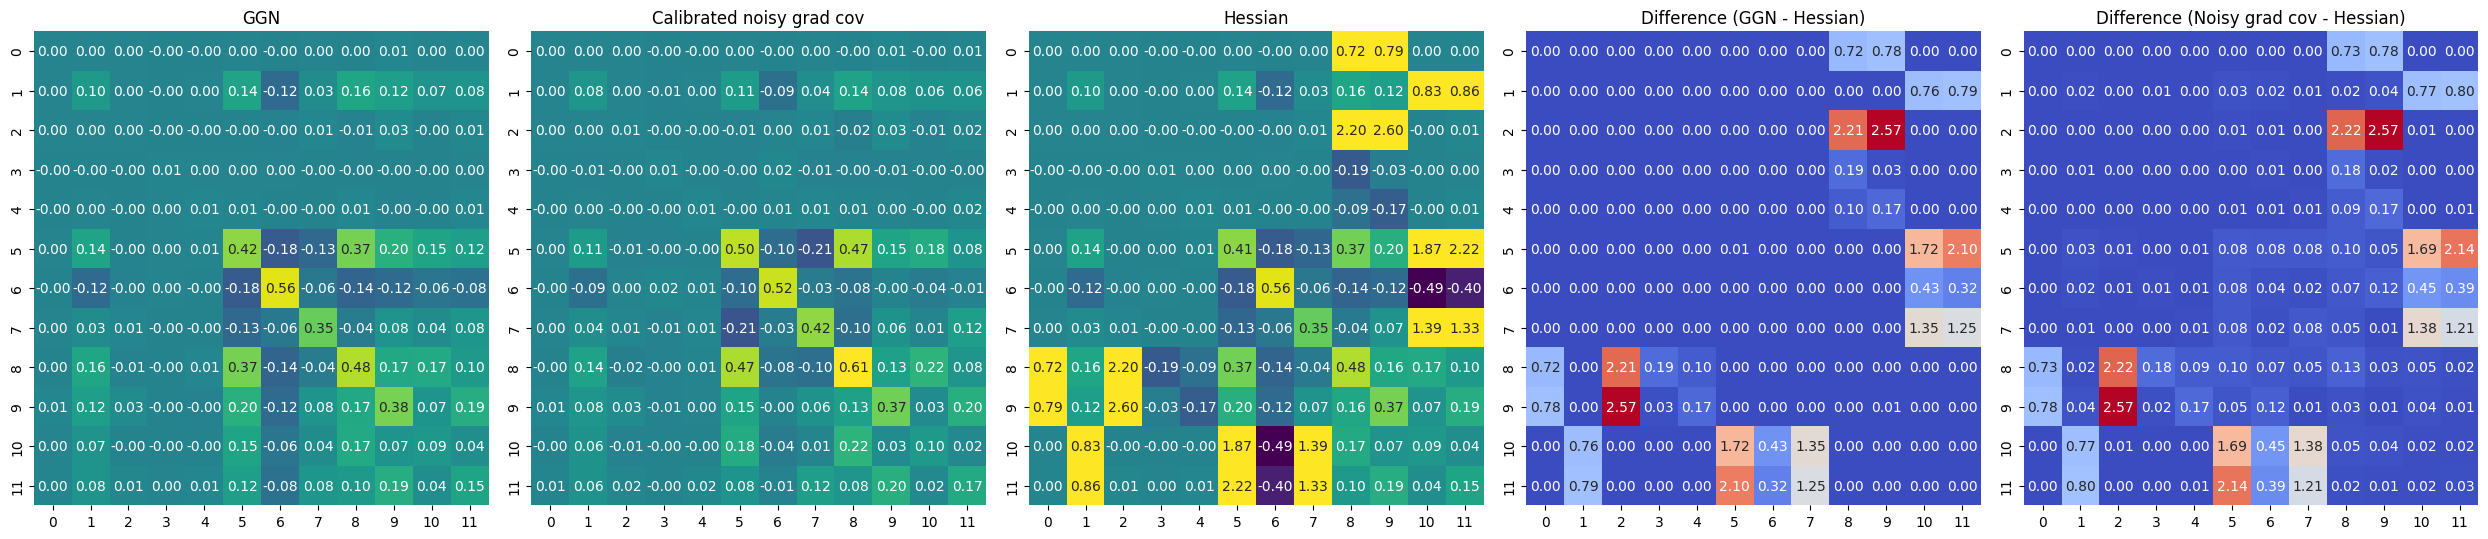

In [5]:
print(f"Classification task: {class_task}")
test_ggn(cnn_gen, X, y, batch_size=128, dist_norm_w=1.1, class_task=class_task)

### Test for regression task

In [6]:
class_task = False
n_features = 8
n_samples = 10000
cnn_gen = CNN1dRegressor(in_channels=1, out_channels=2, kernel_size=3, n_layers=1, seq_len=n_features, pool_size=3)
X, y = generate_data_nn(cnn_gen, n_samples=n_samples, n_features=n_features, noise_std=0.01, scale=3, class_task=class_task)

Classification task: False
Total number of model parameters: 12
torch.Size([12, 12])
Final shape of GGN torch.Size([12, 12])
GNN matr shape = torch.Size([12, 12])
Hessian shape = torch.Size([12, 12])
diff: NC, GN = 13.994551658630371 vs 13.446831703186035
diff_rel: NC, GN  = 0.33068835735321045 vs 0.3177458345890045
block diff: NC, GN = 2.2557520866394043 vs 1.0235062291030772e-06
block diff_rel: NC, GN  = 0.10274723917245865 vs 4.6619678784054486e-08
Hessian eigv:
['-12.20888', '-9.18279', '-0.28951', '0.02572', '0.57242', '2.06559', '2.39777', '4.31772', '4.76820', '8.39242', '13.79144', '42.31947']

Noisy grad cov eigv:
['-0.00000', '0.00000', '0.06107', '0.14181', '0.48940', '1.95128', '2.49247', '3.25132', '3.88729', '5.73455', '9.16349', '31.58719']

GGN eigv:
['-0.00000', '0.00000', '0.05263', '0.10859', '0.44299', '1.97731', '2.26646', '3.90169', '4.48032', '4.75750', '8.44890', '30.53318']

Eigv diff rel (noisy cov vs Hessian) = 0.26312676072120667
Eigv diff rel (GGN vs Hessia

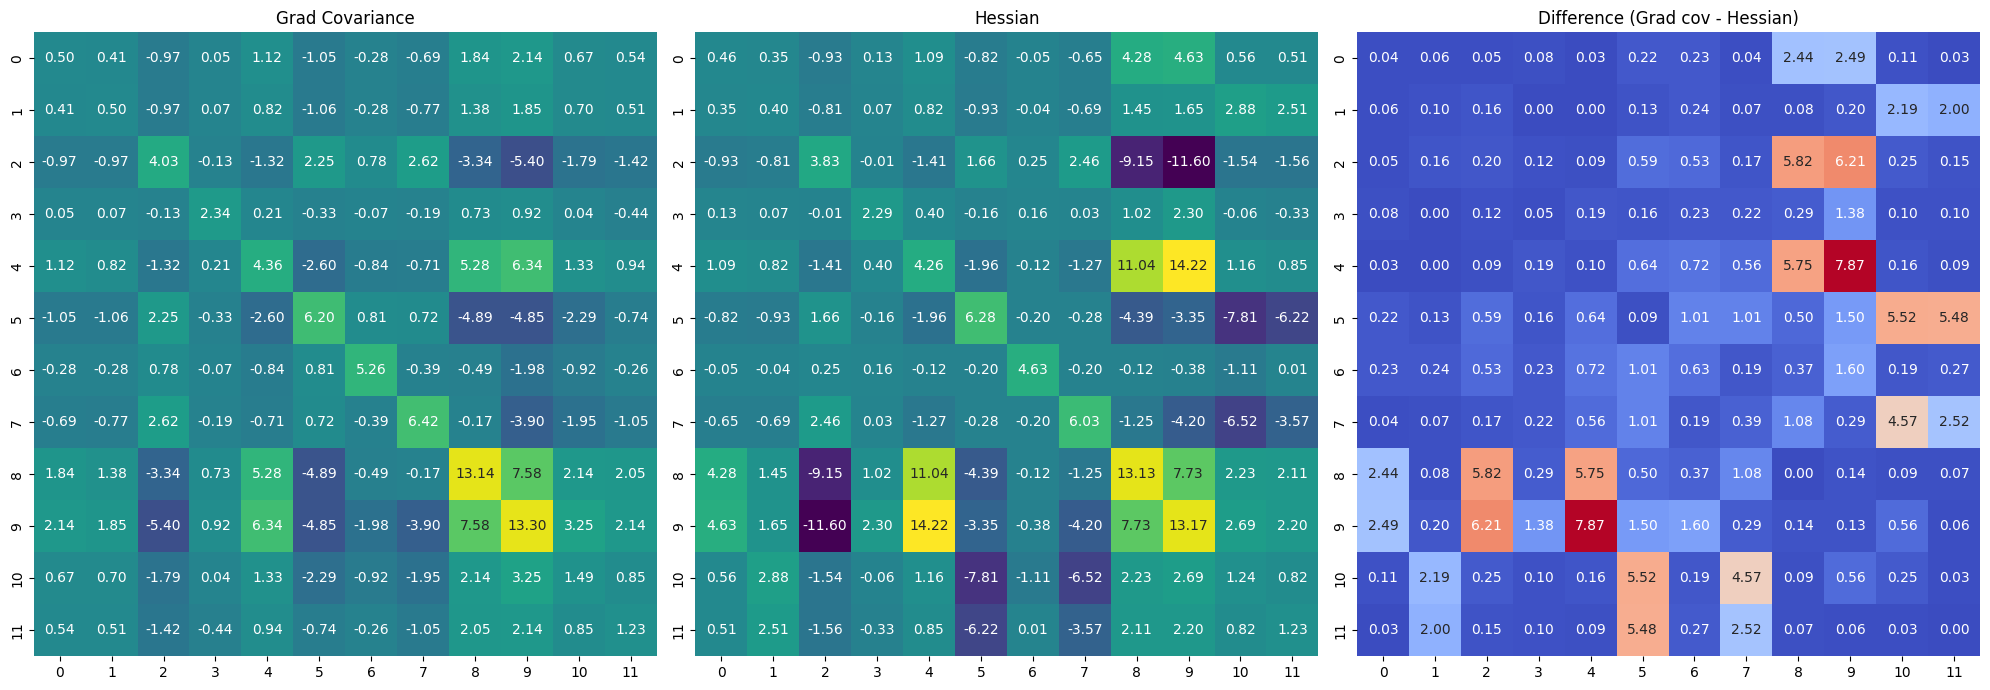

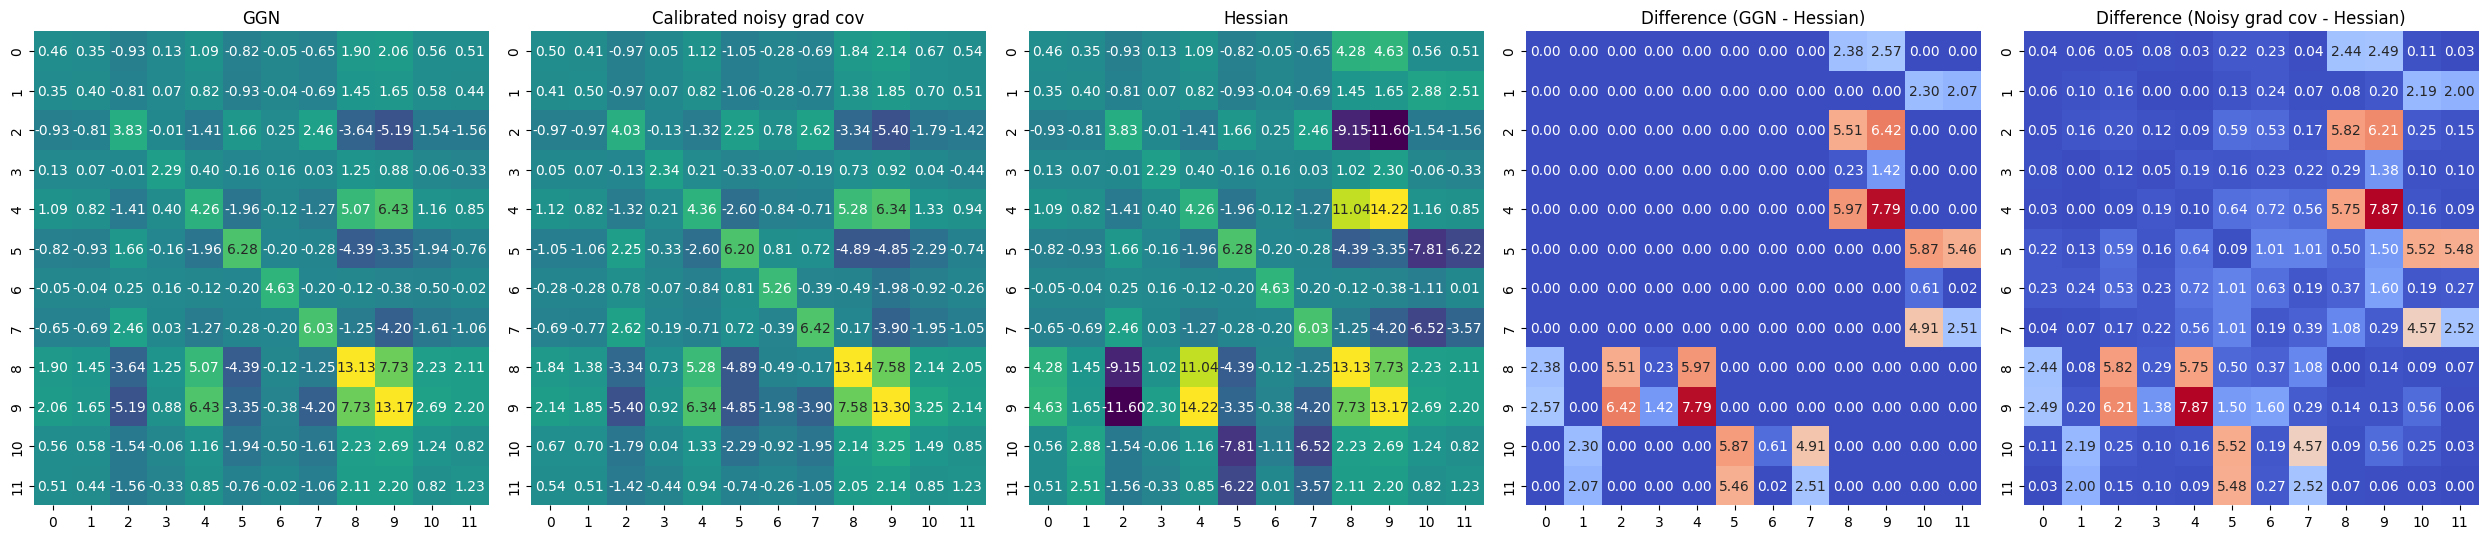

In [7]:
print(f"Classification task: {class_task}")
test_ggn(cnn_gen, X, y, batch_size=128, dist_norm_w=1.1, class_task=class_task)